---
title: "Week 8A: Geospatial Data — Street Networks"
format:
  html:
    toc: true
    toc-depth: 3
    number-sections: true
    code-fold: false
    embed-resources: true
    theme: cosmo
execute:
  enabled: false
---

# Week 8A: Geospatial Data — Street Networks

**Learning goals:** retrieve OSM boundaries and features; compare network types; calculate shortest routes; map walking access to amenities with Pandana.

This notebook retains the step-by-step demonstrations. Work through the cells in order; pause at the questions to predict or interpret the results. The main lesson has two parts: **OSMnx** and **Pandana**.

In [1]:
from pathlib import Path

import altair as alt
import geopandas as gpd
import numpy as np
import pandas as pd
import networkx as nx
from matplotlib import pyplot as plt
from IPython.display import display

lab_dir = Path.cwd()
if not (lab_dir / "data/sidewalk.zip").exists():
    lab_dir = lab_dir / "labs/week-8-network-analysis"
if not lab_dir.exists():
    raise FileNotFoundError("Open this notebook from the lab folder or the course public folder.")

In [2]:
# Keep table previews readable. Do not suppress numerical warnings globally.
pd.options.display.max_columns = 12
pd.options.display.max_colwidth = 60
plt.rcParams.update({"figure.figsize": (9, 6), "font.size": 11})

## Today: Urban street networks and OpenStreetMap (OSM)

- Two tools that make working with OSM data very easy
- What kind of questions can we answer?
    - Street orientations 
    - Mapping event points to streets: car crashes
    - Mapping amenities
    - Network-constrained distances: accessibility

## OSM: what is it?

- Collaborative mapping
- A free editable map of the World
- Sort of like Wikipedia for maps

**Great source of data: street networks and a wealth of amenity information**

https://www.openstreetmap.org

## Working with OSM data

OSM data contain many geometry and tag types. Two complementary tools help us work with them:

- **OSMnx:** retrieve geographic features and model street networks.
- **Pandana:** run network queries efficiently for amenity accessibility.

We also use GeoPandas for tables/maps and Folium for optional interactive maps. OSM is a collaboratively mapped inventory: missing features and uneven coverage affect results.

## Part 1: OSMnx

OSMnx connects OpenStreetMap data with GeoPandas and NetworkX. We will use it to retrieve boundaries, download street networks, and analyze routes and street patterns.

**Before class:** select a kernel with OSMnx 2.x, GeoPandas, NetworkX, Pandana, Altair, NumPy, pandas, and Matplotlib. Optional interactive maps also need Folium and mapclassify. The existing `cache/` folder contains historical OSM responses from October 2025; keep it with the notebook. Uncached queries require internet access and may take several minutes or return different data.

  - [GitHub](https://github.com/gboeing/osmnx)
  - [Introductory Blog Post](https://geoffboeing.com/2016/11/osmnx-python-street-networks/)
  - [Jupyter Notebook Examples](https://github.com/gboeing/osmnx-examples/tree/master/notebooks) ([Binder](https://mybinder.org/v2/gh/gboeing/osmnx-examples/main?urlpath=/tree/notebooks))
  - [Documentation](https://osmnx.readthedocs.io)

In [3]:
# Run this only if packages are missing, then restart the kernel:
# %pip install "osmnx>=2,<3" geopandas networkx pandana altair matplotlib folium mapclassify
# In Jupyter, %pip installs into the active kernel's environment.

In [4]:
import osmnx as ox

if int(ox.__version__.split(".")[0]) < 2:
    raise ImportError("This notebook uses OSMnx 2.x; select or update your kernel.")
ox.settings.use_cache = True
ox.settings.cache_folder = lab_dir / "cache"
ox.settings.log_console = False
print("OSMnx version:", ox.__version__)

OSMnx version: 2.0.6


### 1.1. Getting boundary shapefiles from OSM

Key function: `geocode_to_gdf()` ([docs](https://osmnx.readthedocs.io/en/stable/osmnx.html#osmnx.geocoder.geocode_to_gdf))

We can get the boundary for anything identified as a "place" by OSM.

**Important: Be careful to pass the right place name that OSM needs**

In [5]:
philly = ox.geocode_to_gdf("Philadelphia, PA")

philly.head()

,geometry,bbox_west,bbox_south,bbox_east,bbox_north,place_id,...,type,place_rank,importance,addresstype,name,display_name
0,"POLYGON ((-75.28027 39.97496, -75.28023 39.97489, -75.28...",-75.280266,39.867005,-74.955831,40.137959,331386626,...,administrative,16,0.766493,city,Philadelphia,"Philadelphia, Philadelphia County, Pennsylvania, United ..."


In [6]:
philly.crs

<Geographic 2D CRS: EPSG:4326>
Name: WGS 84
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: World.
- bounds: (-180.0, -90.0, 180.0, 90.0)
Datum: World Geodetic System 1984 ensemble
- Ellipsoid: WGS 84
- Prime Meridian: Greenwich

We can plot it just like any other GeoDataFrame

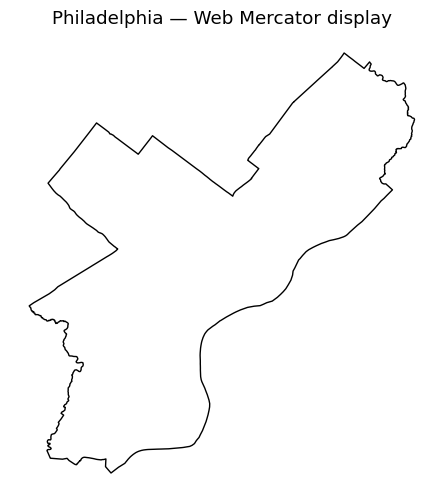

In [7]:
# Web Mercator is useful for web display, but not local distance measurement.
ax = philly.to_crs(epsg=3857).plot(facecolor="none", edgecolor="black")
ax.set_title("Philadelphia — Web Mercator display")
ax.set_axis_off()
plt.show()

### 1.2 Projecting with OSMnx and GeoPandas

For a local study area, `ox.projection.project_gdf()` or `gdf.to_crs(gdf.estimate_utm_crs())` selects a suitable UTM projection. UTM coordinates use meters. A single UTM zone is not appropriate for measurements over a large state or country.

**Compare:** how does the Philadelphia map change from Web Mercator to UTM?

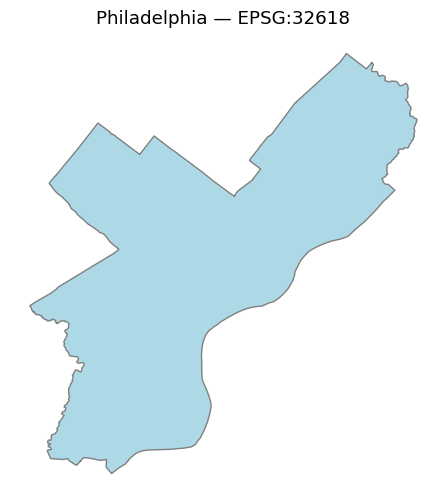

In [8]:
philly_proj = philly.to_crs(philly.estimate_utm_crs())
ax = philly_proj.plot(facecolor="lightblue", edgecolor="gray")
ax.set_title(f"Philadelphia — {philly_proj.crs}")
ax.set_axis_off()
plt.show()

Some more examples:

In [9]:
# Some examples
place1 = ox.geocode_to_gdf("Manhattan, New York City, New York, USA")
place2 = ox.geocode_to_gdf("Miami-Dade County, Florida")
place3 = ox.geocode_to_gdf("Florida, USA")
place4 = ox.geocode_to_gdf("Spain")

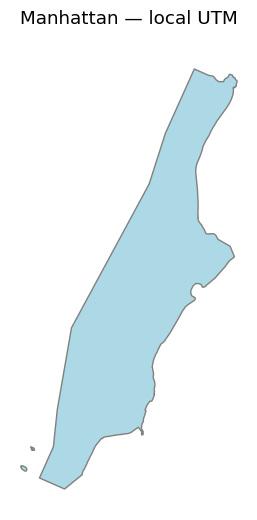

In [10]:
place1_reproj = place1.to_crs(place1.estimate_utm_crs())
ax = place1_reproj.plot(facecolor="lightblue", edgecolor="gray")
ax.set_title("Manhattan — local UTM")
ax.set_axis_off()
plt.show()

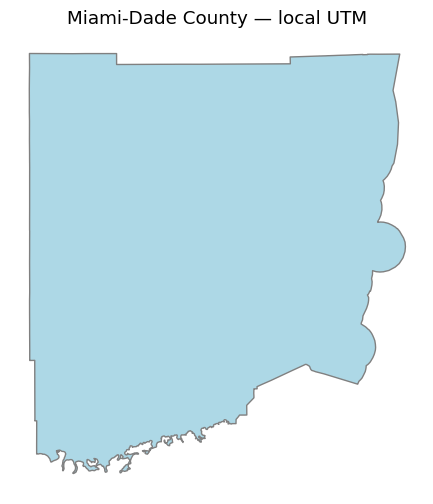

In [11]:
place2_reproj = place2.to_crs(place2.estimate_utm_crs())
ax = place2_reproj.plot(facecolor="lightblue", edgecolor="gray")
ax.set_title("Miami-Dade County — local UTM")
ax.set_axis_off()
plt.show()

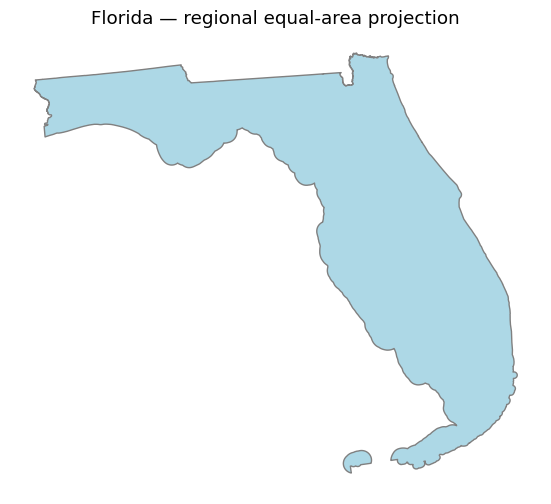

In [12]:
# A regional equal-area CRS is more appropriate for this statewide overview.
place3_reproj = place3.to_crs(epsg=5070)
ax = place3_reproj.plot(facecolor="lightblue", edgecolor="gray")
ax.set_title("Florida — regional equal-area projection")
ax.set_axis_off()
plt.show()

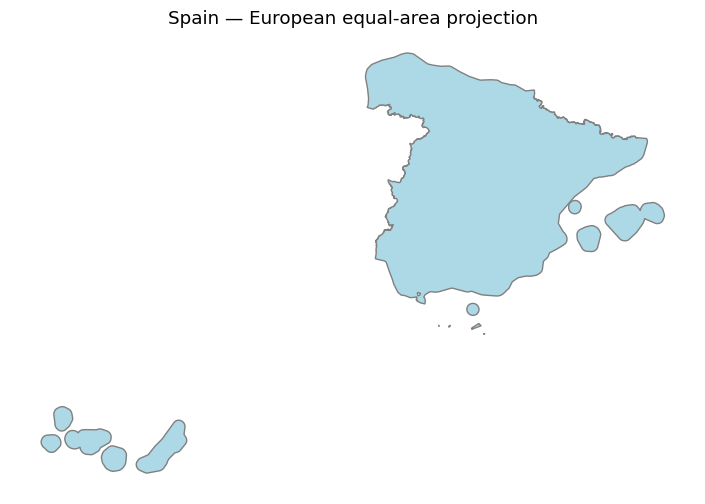

In [13]:
# Use a European equal-area projection for this country-scale overview.
place4_reproj = place4.to_crs(epsg=3035)
ax = place4_reproj.plot(facecolor="lightblue", edgecolor="gray")
ax.set_title("Spain — European equal-area projection")
ax.set_axis_off()
plt.show()

### 1.3 Downloading OSM features

Choose a query method that matches your study area:

| Function | Area supplied |
|---|---|
| `ox.features_from_place()` | Named place boundary |
| `ox.features_from_address()` | Distance around a geocoded address |
| `ox.features_from_bbox()` | `(left, bottom, right, top)` in longitude/latitude for OSMnx 2.x |
| `ox.features_from_point()` | Distance around `(latitude, longitude)` |
| `ox.features_from_polygon()` | Polygon in EPSG:4326 |

The following examples retain several tag queries so you can compare the results. [OSMnx reference](https://osmnx.readthedocs.io/en/stable/user-reference.html)

::: {.callout-note}
### About OSM features

**Important reference:** https://wiki.openstreetmap.org/wiki/Map_Features

- OSM uses a *tagging* system to categorize different map features
- The main feature categories are available on the OSM Wikipedia
    - Examples: 'amenity', 'building', 'landuse', 'highway'
- There are specific sub-categories for each feature type too:
    - Amenity examples: 'bar', 'college', 'library'

In the language of OSM, the "key" is the main feature category (e.g., amenity) and the "value" is the sub-category type (e.g., "bar")
:::

OSMnx uses a dictionary of tag keys and values. `True` matches any value for that key; a list matches any listed value. Multiple tags are combined as a union, not an intersection. The examples below illustrate progressively narrower queries.

In [14]:
# Get all amenities in Philadelphia
amenities = ox.features_from_place("Philadelphia, PA", tags={"amenity": True})

In [15]:
len(amenities)

15759

In [16]:
amenities.head()

geometry           amenity      brand  \
element id                                                                   
node    109811385  POINT (-75.19487 40.05846)             bench        NaN   
        110237774   POINT (-75.15662 39.9504)  parking_entrance        NaN   
        274216093  POINT (-75.19125 39.95764)               atm   Citibank   
        274217596  POINT (-75.19229 39.95301)              cafe  Starbucks   
        313440966  POINT (-75.16694 39.96394)       car_sharing        NaN   

                  brand:wikidata       name  operator  ... name:vi  \
element id                                             ...           
node    109811385            NaN        NaN       NaN  ...     NaN   
        110237774            NaN        NaN       NaN  ...     NaN   
        274216093        Q857063   Citibank  Citibank  ...     NaN   
        274217596         Q37158  Starbucks       NaN  ...     NaN   
        313440966            NaN        NaN       NaN  ...     NaN   

                  isced:level pedagogy school:gender statue crossing:markings  
element id                                                                     
node    109811385         NaN      NaN           NaN    NaN               NaN  
        110237774         NaN      NaN           NaN    NaN               NaN  
        274216093         NaN      NaN           NaN    NaN               NaN  
        274217596         NaN      NaN           NaN    NaN               NaN  
        313440966         NaN      NaN           NaN    NaN               NaN  

[5 rows x 474 columns]

In [17]:
# Get all bars in philadelphia
bars = ox.features_from_place("Philadelphia, PA", tags={"amenity": "bar"})

In [18]:
len(bars)

165

In [19]:
bars.head()

geometry addr:housenumber  \
element id                                                        
node    1033935437  POINT (-75.17552 39.95242)             2101   
        1167079387   POINT (-75.14925 39.9417)              401   
        1204761128  POINT (-75.16363 39.92685)              NaN   
        1424271155  POINT (-75.14909 39.94152)              344   
        1475230378  POINT (-75.14002 39.96627)             1001   

                         addr:street amenity    contact:phone  \
element id                                                      
node    1033935437   Chestnut Street     bar  +1 215-568-3355   
        1167079387      South Street     bar  +1 215-925-6455   
        1204761128               NaN     bar              NaN   
        1424271155      South Street     bar              NaN   
        1475230378  North 2nd Street     bar              NaN   

                                                            contact:website  \
element id                                                                    
node    1033935437  https://mixbarandgrillphilly.com/location/mix-bar-grill   
        1167079387                       https://www.milkboy.tv/southstreet   
        1204761128                                                      NaN   
        1424271155                                                      NaN   
        1475230378                                                      NaN   

                    ... nonsquare shop contact:tiktok contact:twitter level  \
element id          ...                                                       
node    1033935437  ...       NaN  NaN            NaN             NaN   NaN   
        1167079387  ...       NaN  NaN            NaN             NaN   NaN   
        1204761128  ...       NaN  NaN            NaN             NaN   NaN   
        1424271155  ...       NaN  NaN            NaN             NaN   NaN   
        1475230378  ...       NaN  NaN            NaN             NaN   NaN   

                   designation  
element id                      
node    1033935437         NaN  
        1167079387         NaN  
        1204761128         NaN  
        1424271155         NaN  
        1475230378         NaN  

[5 rows x 66 columns]

In [20]:
# Get bar, pub, and restaurant features in Philadelphia
food_and_drink = ox.features_from_place(
    "Philadelphia, PA", tags={"amenity": ["pub", "bar", "restaurant"]}
)

In [21]:
len(food_and_drink)

1157

In [22]:
food_and_drink.head()

geometry     addr:city addr:housenumber  \
element id                                                                     
node    333786044  POINT (-75.15893 39.94086)  Philadelphia              735   
        343293806  POINT (-75.15946 39.96073)  Philadelphia              501   
        566683522  POINT (-75.15755 39.96205)  Philadelphia             1139   
        596230881  POINT (-75.18682 40.05492)           NaN              NaN   
        596245658   POINT (-75.19035 40.0592)  Philadelphia             7136   

                  addr:postcode addr:state           addr:street  ... theme  \
element id                                                        ...         
node    333786044         19147         PA     South 10th Street  ...   NaN   
        343293806         19123         PA     North 13th Street  ...   NaN   
        566683522         19123        NaN  Spring Garden Street  ...   NaN   
        596230881           NaN        NaN                   NaN  ...   NaN   
        596245658         19119         PA     Germantown Avenue  ...   NaN   

                  building:colour building:material roof:shape contact:tiktok  \
element id                                                                      
node    333786044             NaN               NaN        NaN            NaN   
        343293806             NaN               NaN        NaN            NaN   
        566683522             NaN               NaN        NaN            NaN   
        596230881             NaN               NaN        NaN            NaN   
        596245658             NaN               NaN        NaN            NaN   

                  house  
element id               
node    333786044   NaN  
        343293806   NaN  
        566683522   NaN  
        596230881   NaN  
        596245658   NaN  

[5 rows x 155 columns]

In [23]:
# Get bus stop features
bus_stops = ox.features_from_place("Philadelphia, PA", tags={"highway": "bus_stop"})

In [24]:
len(bus_stops)

334

In [25]:
bus_stops.head()

geometry bench  bus covered   highway  \
element id                                                                    
node    361011456   POINT (-75.16166 39.95223)   yes  yes     yes  bus_stop   
        750281693   POINT (-75.07732 40.01797)   NaN  yes     NaN  bus_stop   
        768271130   POINT (-75.20726 40.01487)   NaN  yes     NaN  bus_stop   
        1015342921   POINT (-75.18187 39.9664)   NaN  yes     NaN  bus_stop   
        1015342926   POINT (-75.18024 39.9667)   NaN  yes     NaN  bus_stop   

                                                 name  ... addr:postcode  \
element id                                             ...                 
node    361011456                 13th St & Market St  ...           NaN   
        750281693                                 NaN  ...           NaN   
        768271130   Wissahickon Transportation Center  ...           NaN   
        1015342921                                NaN  ...           NaN   
        1015342926                                NaN  ...           NaN   

                   addr:state ref:signed fixme sign panoramax  
element id                                                     
node    361011456         NaN        NaN   NaN  NaN       NaN  
        750281693         NaN        NaN   NaN  NaN       NaN  
        768271130         NaN        NaN   NaN  NaN       NaN  
        1015342921        NaN        NaN   NaN  NaN       NaN  
        1015342926        NaN        NaN   NaN  NaN       NaN  

[5 rows x 45 columns]

In [26]:
# Get commercial and retail landuse features
landuse = ox.features_from_place(
    "Philadelphia, PA", tags={"landuse": ["commercial", "retail"]}
)

In [27]:
len(landuse)

349

Let's plot the land use features:

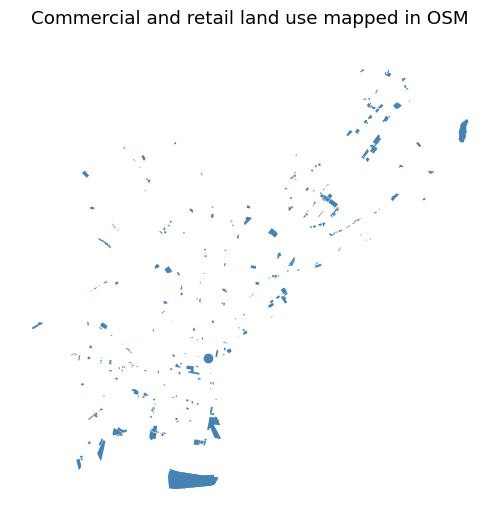

In [28]:
fig, ax = plt.subplots(figsize=(10, 6))
landuse.to_crs(philly_proj.crs).plot(ax=ax, color="steelblue")
ax.set_title("Commercial and retail land use mapped in OSM")
ax.set_axis_off()
plt.show()

### 1.4 Downloading street networks

The corresponding `graph_from_place`, `graph_from_address`, `graph_from_bbox`, `graph_from_point`, and `graph_from_polygon` functions return NetworkX graphs.

Specify the travel mode with `network_type`. A distance-based download defines a study extent; it is not a network-distance service area. Larger areas need more download time and memory.

#### Street network around an address

Get streets within 500 meters of the center of Center City

In [29]:
G = ox.graph_from_address("Center City, Philadelphia, PA", dist=500, network_type="all")

Project and plot it:

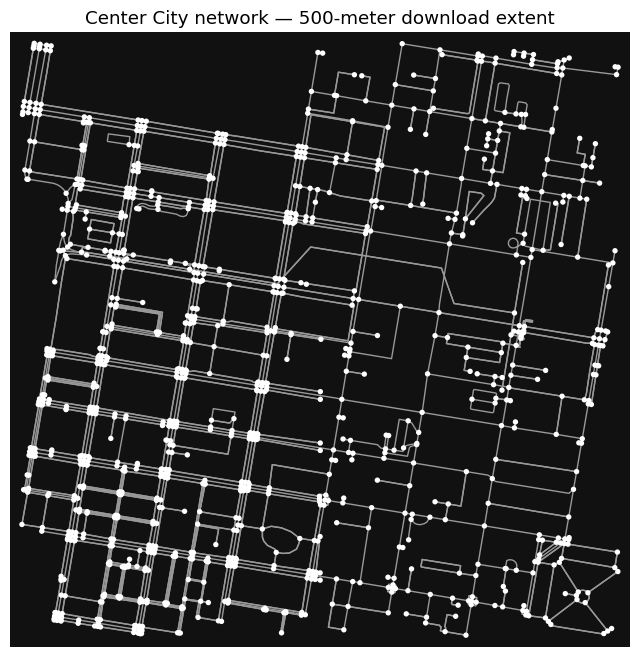

In [30]:
G_projected = ox.projection.project_graph(G)
fig, ax = ox.plot_graph(G_projected, show=False, close=False)
ax.set_title("Center City network — 500-meter download extent")
plt.show()

Remove the nodes:

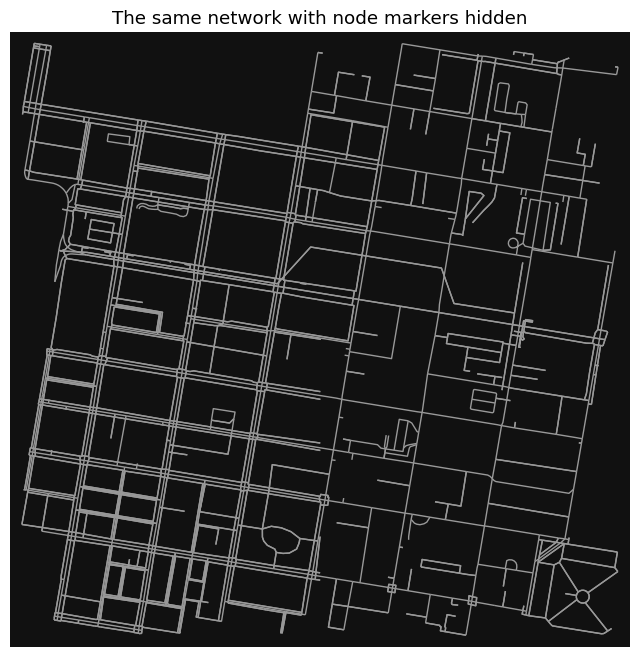

In [31]:
fig, ax = ox.plot_graph(G_projected, node_size=0, show=False, close=False)
ax.set_title("The same network with node markers hidden")
plt.show()

Let's zoom out to 2,000 meters. This will take a little longer.

In [32]:
G = ox.graph_from_address("Center City, Philadelphia, PA", dist=2000, network_type="all")
G_projected = ox.projection.project_graph(G)

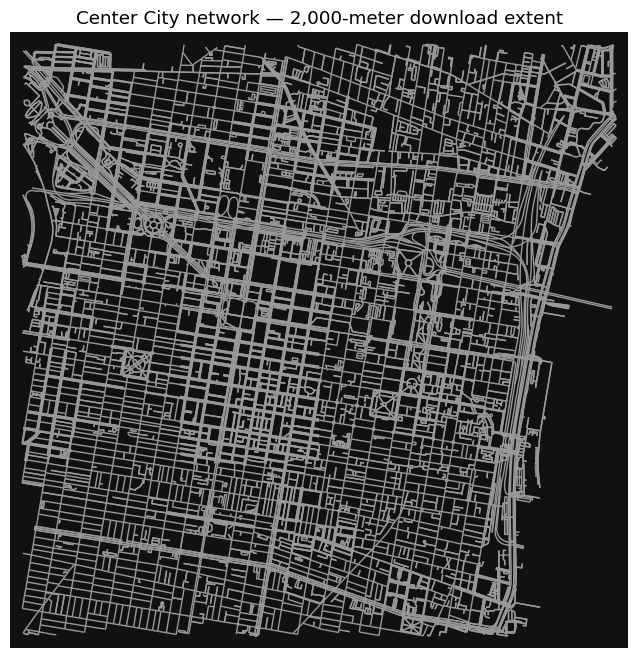

In [33]:
fig, ax = ox.plot_graph(G_projected, node_size=0, show=False, close=False)
ax.set_title("Center City network — 2,000-meter download extent")
plt.show()

#### Getting different network types

- `drive`: streets for driving, respecting one-way direction.
- `drive_service`: driving streets including service roads.
- `walk`: pedestrian streets and paths, modeled as bidirectional.
- `bike`: streets and paths available to bicycles.
- `all`: public and private-access streets and paths currently in use.
- `all_public`: public-access streets and paths (OSMnx 2.x).

We explicitly select `drive` and `walk` below. **Predict:** which network will contain more connections?

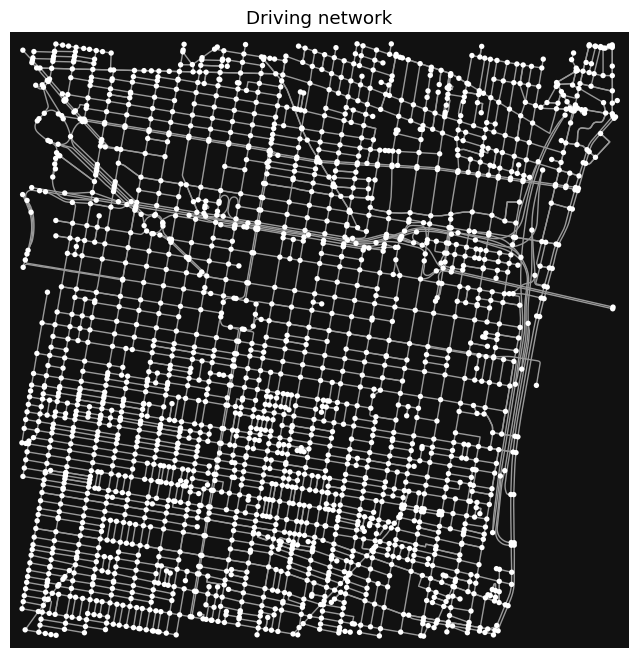

In [34]:
G_drive = ox.graph_from_address("Center City, Philadelphia, PA", network_type="drive", dist=2000)
fig, ax = ox.plot_graph(ox.projection.project_graph(G_drive), show=False, close=False)
ax.set_title("Driving network")
plt.show()

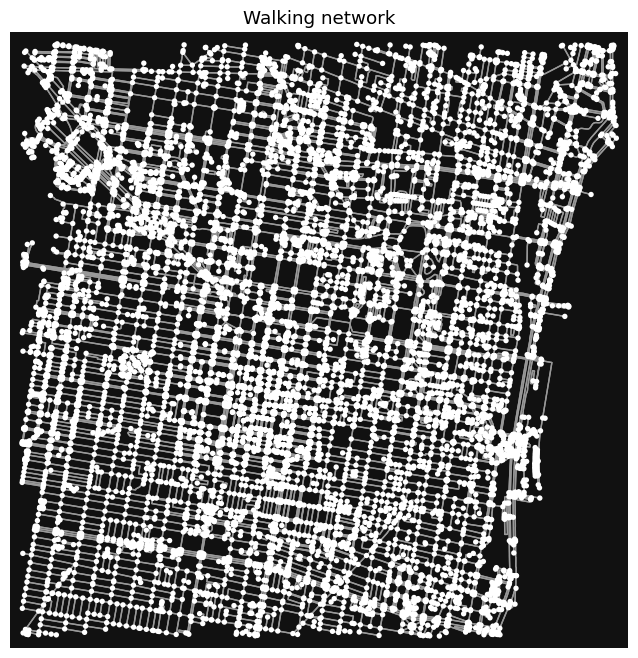

In [35]:
G_walk = ox.graph_from_address("Center City, Philadelphia, PA", network_type="walk", dist=2000)
fig, ax = ox.plot_graph(ox.projection.project_graph(G_walk), show=False, close=False)
ax.set_title("Walking network")
plt.show()

#### Street network within a place boundary

Use `graph_from_place()` to get the streets within a specific OSM place.

::: {.callout-caution}

A couple of things to watch out for: 
1. The place query has to be resolved by OSM.
2. If the place is a big city, you might be downloading a lot of data!

:::

Let's check out the street network for Berkeley, CA:

In [36]:
berkeley = ox.graph_from_place("Berkeley, California, USA", network_type="all")

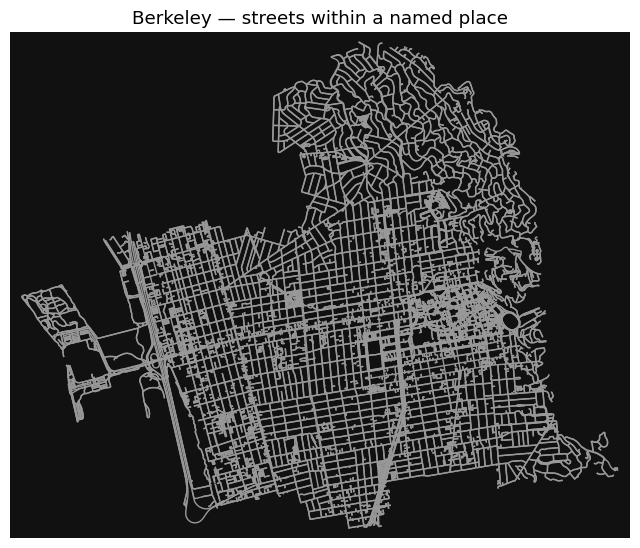

In [37]:
fig, ax = ox.plot_graph(ox.projection.project_graph(berkeley), node_size=0, show=False, close=False)
ax.set_title("Berkeley — streets within a named place")
plt.show()

#### Streets within a specific polygon

**Example:** Let's download all streets within Center City. We will use the "Central" planning district as a proxy for this area. The city's planning districts are available on [Open Data Philly](https://opendataphilly.org/datasets/planning-districts/).

In [38]:
# Prefer the local classroom copy; the source URL is retained for reference.
planning_path = lab_dir / "data/week8a/planning-districts.geojson"
planning_url = "https://opendata.arcgis.com/datasets/0960ea0f38f44146bb562f2b212075aa_0.geojson"
planning_districts = gpd.read_file(planning_path if planning_path.exists() else planning_url)
planning_districts = planning_districts.to_crs(4326)

In [39]:
len(planning_districts)

18

In [40]:
planning_districts.head()

,objectid,dist_name,abbrev,Shape__Area,Shape__Length,geometry
0,1,River Wards,RW,3.338947e+07,26635.524113,"POLYGON ((-75.09798 40.00496, -75.09687 40.00557, -75.09..."
1,2,North Delaware,NDEL,4.285306e+07,35525.335312,"POLYGON ((-74.98159 40.05363, -74.98139 40.0536, -74.981..."
2,3,Lower Far Northeast,LFNE,4.875252e+07,36958.071333,"POLYGON ((-74.96443 40.11728, -74.96434 40.11727, -74.96..."
3,4,Central,CTR,2.822133e+07,28401.823065,"POLYGON ((-75.14791 39.96733, -75.14715 39.96714, -75.14..."
4,5,University Southwest,USW,2.051763e+07,25957.938149,"POLYGON ((-75.18742 39.96338, -75.18644 39.96349, -75.18..."


Trim to the central district:

In [41]:
central_district = planning_districts.loc[planning_districts["dist_name"].eq("Central")].copy()
if len(central_district) != 1:
    raise ValueError("Expected one Central planning district; inspect the source table.")

And plot it:

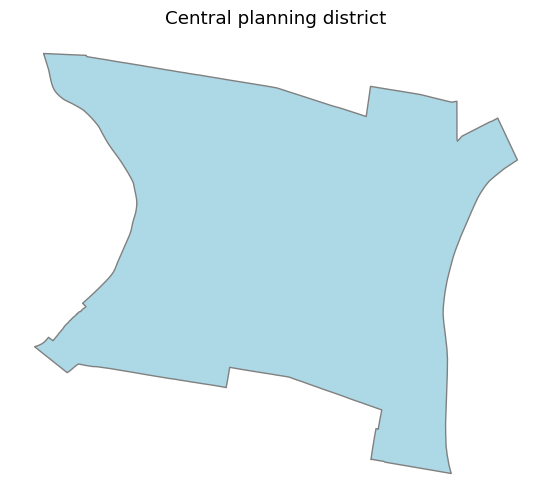

In [42]:
central_district_reproj = central_district.to_crs(central_district.estimate_utm_crs())
ax = central_district_reproj.plot(facecolor="lightblue", edgecolor="gray")
ax.set_title("Central planning district")
ax.set_axis_off()
plt.show()

In [43]:
central_district[["dist_name", "geometry"]], central_district_reproj.crs

(  dist_name                                                     geometry
 3   Central  POLYGON ((-75.14791 39.96733, -75.14715 39.96714, -75.14...,
 <Projected CRS: EPSG:32618>
 Name: WGS 84 / UTM zone 18N
 Axis Info [cartesian]:
 - E[east]: Easting (metre)
 - N[north]: Northing (metre)
 Area of Use:
 - name: Between 78°W and 72°W, northern hemisphere between equator and 84°N, onshore and offshore. Bahamas. Canada - Nunavut; Ontario; Quebec. Colombia. Cuba. Ecuador. Greenland. Haiti. Jamaica. Panama. Turks and Caicos Islands. United States (USA). Venezuela.
 - bounds: (-78.0, 0.0, -72.0, 84.0)
 Coordinate Operation:
 - name: UTM zone 18N
 - method: Transverse Mercator
 Datum: World Geodetic System 1984 ensemble
 - Ellipsoid: WGS 84
 - Prime Meridian: Greenwich)

Extract the one polygon with `.iloc[0]`. Its CRS must be EPSG:4326 for the OSMnx polygon query; keep the projected copy for measurements and plotting.

In [44]:
center_city_outline = central_district.geometry.iloc[0]
center_city_outline, type(center_city_outline)

(<POLYGON ((-75.148 39.967, -75.147 39.967, -75.147 39.969, -75.147 39.97, -7...>,
 shapely.geometry.polygon.Polygon)

Now, let's use `ox.graph_from_polygon()` to extract streets within this polygon. 

In [45]:
# Get the graph
G_cc = ox.graph_from_polygon(center_city_outline, network_type="drive")

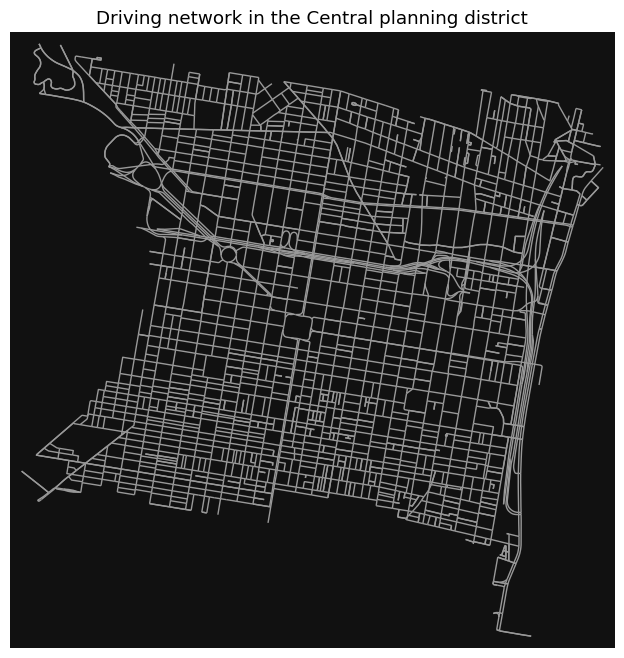

In [46]:
fig, ax = ox.plot_graph(ox.projection.project_graph(G_cc), node_size=0, show=False, close=False)
ax.set_title("Driving network in the Central planning district")
plt.show()

### 1.5 Converting from a graph to a GeoDataFrame

`ox.convert.graph_to_gdfs()` returns node (point) and edge (line) GeoDataFrames. OSMnx uses a `MultiDiGraph`: directed edges can have parallel alternatives. Edge rows are indexed by `(u, v, key)` so those alternatives stay distinct.

In [47]:
type(G_cc)

networkx.classes.multidigraph.MultiDiGraph

In [48]:
cc_edges = ox.convert.graph_to_gdfs(G_cc, edges=True, nodes=False)

In [49]:
# we have lots of data associated with each edge!
cc_edges.head()

osmid      highway lanes                   name  \
u         v         key                                                        
109727439 109911666 0    132508434  residential     1      Bainbridge Street   
109727448 109727439 0     12109011  residential   NaN  South Colorado Street   
          110034229 0     12159387  residential   NaN       Fitzwater Street   
109727507 110024052 0    193364514  residential   NaN       Carpenter Street   
109728761 110274344 0    672312336  residential   NaN           Brown Street   

                         oneway reversed  ...  bridge tunnel width service  \
u         v         key                   ...                                
109727439 109911666 0      True    False  ...     NaN    NaN   NaN     NaN   
109727448 109727439 0      True    False  ...     NaN    NaN   NaN     NaN   
          110034229 0      True    False  ...     NaN    NaN   NaN     NaN   
109727507 110024052 0      True    False  ...     NaN    NaN   NaN     NaN   
109728761 110274344 0      True    False  ...     NaN    NaN   NaN     NaN   

                        access junction  
u         v         key                  
109727439 109911666 0      NaN      NaN  
109727448 109727439 0      NaN      NaN  
          110034229 0      NaN      NaN  
109727507 110024052 0      NaN      NaN  
109728761 110274344 0      NaN      NaN  

[5 rows x 16 columns]

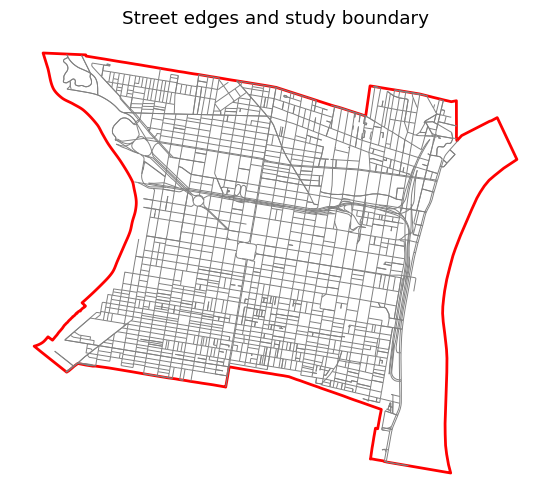

In [50]:
metric_crs = central_district_reproj.crs
ax = cc_edges.to_crs(metric_crs).plot(color="gray", linewidth=0.7)
boundary = gpd.GeoSeries([center_city_outline], crs="EPSG:4326")
boundary.to_crs(metric_crs).plot(ax=ax, facecolor="none", edgecolor="red", linewidth=2)
ax.set_title("Street edges and study boundary")
ax.set_axis_off()
plt.show()

**Interactive map demonstration:** GeoPandas `.explore()` creates a Folium map. Enable the following switch to run the interactive examples. They need Folium, mapclassify, and internet access for web-map assets and tiles. Static maps remain available in the HTML when the switch is off.

In [51]:
SHOW_INTERACTIVE_MAPS = False
if SHOW_INTERACTIVE_MAPS:
    display(cc_edges.explore(tiles="CartoDB positron"))
else:
    print("Set SHOW_INTERACTIVE_MAPS = True to display the interactive street map.")

Set SHOW_INTERACTIVE_MAPS = True to display the interactive street map.


### 1.6 What can we do with the graph?

- Network-based statistics
- Routing
- Street orientations
- Visualizing crashes

And much more: see the [OSMnx repository of Jupyter notebook examples](https://github.com/gboeing/osmnx-examples/tree/master/notebooks)

#### Street orientations

A [great blog post](https://geoffboeing.com/2019/09/urban-street-network-orientation/) on street orientations across different US and global cities. 

One of my favorite examples of data viz, using matplotlib for *radial histograms* of street orientations...



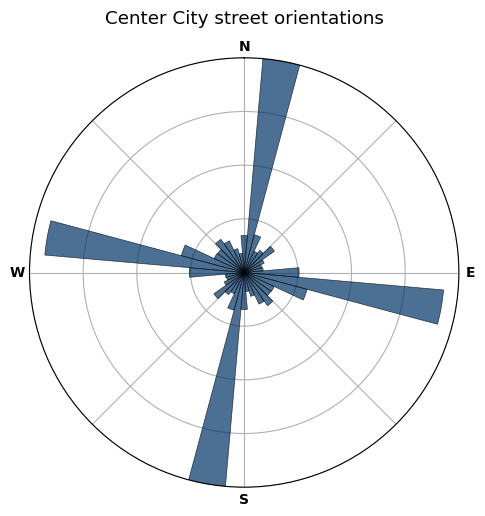

In [52]:
G_bearings = ox.bearing.add_edge_bearings(G_cc)
G_undirected = ox.convert.to_undirected(G_bearings)
fig, ax = ox.plot.plot_orientation(G_undirected, figsize=(5, 5))
ax.set_title("Center City street orientations", pad=25)
plt.show()

This histogram uses an unprojected, undirected graph so bearings describe physical streets without double-counting directed copies. **Discuss:** what do the peaks reveal about the street grid? See the [OSMnx example notebooks](https://github.com/gboeing/osmnx-examples) for comparisons across cities.

#### Network statistics

`ox.stats.basic_stats()` reports node, edge, and physical-street measures. Directed edge counts are not the same as unique physical-street counts. Lengths supplied by OSMnx are in meters, even when graph coordinates are longitude/latitude.

In [53]:
network_stats = ox.stats.basic_stats(G_cc)
pd.Series(network_stats, name="value").to_frame()

,value
n,2097
m,4027
k_avg,3.840725
edge_length_total,357852.730781
edge_length_avg,88.863355
streets_per_node_avg,3.407248
streets_per_node_counts,"{0: 0, 1: 61, 2: 12, 3: 1058, 4: 949, 5: 13, 6: 3, 7: 1}"
streets_per_node_proportions,"{0: 0.0, 1: 0.029089175011921792, 2: 0.00572246065808297..."
intersection_count,2036
street_length_total,311421.493192


#### Finding the shortest route

Let's calculate the shortest route between [the Art Museum](https://www.openstreetmap.org/way/28533972) and the [Liberty Bell](https://www.openstreetmap.org/node/1207480649).

We'll need to download all amenities in Philadelphia of type "tourism".

- The `ox.features_from_place()` can download OSM features with a specific tag
- You can consult the OSM pages ([the Art Museum](https://www.openstreetmap.org/way/28533972) and [Liberty Bell](https://www.openstreetmap.org/node/1207480649)) for each feature for additional info
- Both features are categorized as "tourism" in the OSM data — use the "tags" keyword to select this category

The supplied `tourism.gpkg` is a September 2026 classroom copy. It keeps this example reproducible; the live query remains in the following cell as a fallback.

In [54]:
# Use the classroom copy, or retain the original live OSM query if it is absent.
tourism_path = lab_dir / "data/week8a/tourism.gpkg"
if tourism_path.exists():
    philly_tourism = gpd.read_file(tourism_path, layer="tourism").set_index(["element", "id"])
else:
    philly_tourism = ox.features_from_place("Philadelphia, PA", tags={"tourism": True})

In [55]:
len(philly_tourism)

1052

In [56]:
philly_tourism.head()

name  \
element id                                                                       
node    357371322                                        Bird Lake Picnic Area   
        360500844                                           Hilton Inn at Penn   
        360515304                                                Robert Morris   
        360542779                                        Mario the Magnificent   
        360777728  Pennsylvania Historical Marker: ENIAC, first all purpose...   

                       tourism                    geometry  
element id                                                  
node    357371322  picnic_site    POINT (-75.1958 39.9697)  
        360500844        hotel  POINT (-75.19582 39.95352)  
        360515304      artwork   POINT (-75.1486 39.94771)  
        360542779      artwork   POINT (-75.18932 39.9554)  
        360777728  information   POINT (-75.19021 39.9523)

In [57]:
philly_tourism.loc[philly_tourism["name"].str.contains("Art", case=False, na=False), ["name", "geometry"]]

name  \
element id                                                                         
node    367974278                                 La Salle University Art Museum   
        3775151108          Club Quarters Hotel Rittenhouse Square, Philadelphia   
        4064343335                               Soft Illusions Fine Art Gallery   
        5368454121                                 Institute of Contemporary Art   
        5718906477                                    Art Making Machine Studios   
        6639391809                             Philadelphia Museum of Jewish Art   
        6680708848                                      Romanian Folk Art Museum   
        9904602517                                            Winmont Apartments   
        12188327106                                              Arch Enemy Arts   
        12193292355                                            Twelve Gates Arts   
        12222614599                                Larry Becker Contemporary Art   
        12235452452                                       Museum for Art in Wood   
        12288787985                                             Art on the Ridge   
way     28533972                                      Philadelphia Museum of Art   
        89434182                                           Commandant's Quarters   
        333931830                          Pennsylvania Academy of the Fine Arts   
        592399944    Extended Stay America - Philadelphia - Airport - Bartram...   
        988345364                                            Woodmere Art Museum   

                                                                        geometry  
element id                                                                        
node    367974278                                      POINT (-75.1524 40.03748)  
        3775151108                                    POINT (-75.16851 39.95134)  
        4064343335                                    POINT (-75.22113 40.02427)  
        5368454121                                    POINT (-75.19477 39.95406)  
        5718906477                                    POINT (-75.13058 39.99573)  
        6639391809                                    POINT (-75.16088 39.96383)  
        6680708848                                    POINT (-75.16833 39.94733)  
        9904602517                                    POINT (-75.04059 40.07445)  
        12188327106                                   POINT (-75.14215 39.95191)  
        12193292355                                    POINT (-75.14336 39.9522)  
        12222614599                                   POINT (-75.14334 39.95113)  
        12235452452                                   POINT (-75.14486 39.95339)  
        12288787985                                   POINT (-75.21664 40.03501)  
way     28533972     POLYGON ((-75.18117 39.96468, -75.18141 39.96486, -75.18...  
        89434182     POLYGON ((-75.17721 39.89669, -75.17709 39.89667, -75.17...  
        333931830    POLYGON ((-75.1641 39.95543, -75.16416 39.95516, -75.163...  
        592399944    POLYGON ((-75.24837 39.88659, -75.24845 39.8865, -75.248...  
        988345364    POLYGON ((-75.21927 40.08319, -75.21932 40.08319, -75.21...

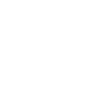

In [58]:
museum_matches = philly_tourism.loc[
    philly_tourism["name"].isin(["Philadelphia Art Museum", "Philadelphia Museum of Art"])
]
if len(museum_matches) != 1:
    raise ValueError("Inspect museum_matches and select the intended OSM feature.")
art_museum = museum_matches.iloc[0]
art_museum.geometry

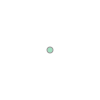

In [59]:
bell_matches = philly_tourism.loc[philly_tourism["name"].eq("Liberty Bell")]
if len(bell_matches) != 1:
    raise ValueError("Inspect bell_matches and select the intended OSM feature.")
liberty_bell = bell_matches.iloc[0]
liberty_bell.geometry

Extract longitude and latitude for the two locations. For a building polygon, calculate an interior representative point in the projected CRS and transform it back to EPSG:4326. This avoids treating degrees as planar coordinates, but does not identify a verified entrance or curbside access point.

In [60]:
bell_point = bell_matches.to_crs(metric_crs).geometry.representative_point().to_crs(4326).iloc[0]
liberty_bell_x, liberty_bell_y = bell_point.x, bell_point.y

In [61]:
museum_point = museum_matches.to_crs(metric_crs).geometry.representative_point().to_crs(4326).iloc[0]
art_museum_x, art_museum_y = museum_point.x, museum_point.y

Find the nearest nodes on our OSMnx graph, using the `ox.nearest_nodes()` function


In [62]:
# In Jupyter, ox.distance.nearest_nodes? opens the full help panel.
import inspect
print(inspect.signature(ox.distance.nearest_nodes))
print("X is longitude/easting; Y is latitude/northing. Match the graph CRS.")

(G: 'nx.MultiDiGraph', X: 'float | Iterable[float]', Y: 'float | Iterable[float]', *, return_dist: 'bool' = False) -> 'int | npt.NDArray[np.int64] | tuple[int, float] | tuple[npt.NDArray[np.int64], npt.NDArray[np.float64]]'
X is longitude/easting; Y is latitude/northing. Match the graph CRS.


In [63]:
art_museum_y

39.965564759517356

In [64]:
orig_node, origin_snap_m = ox.distance.nearest_nodes(
    G_cc, X=liberty_bell_x, Y=liberty_bell_y, return_dist=True
)
dest_node, destination_snap_m = ox.distance.nearest_nodes(
    G_cc, X=art_museum_x, Y=art_museum_y, return_dist=True
)
print(f"Snap distances: origin {origin_snap_m:.1f} m; destination {destination_snap_m:.1f} m")
if orig_node == dest_node or not nx.has_path(G_cc, orig_node, dest_node):
    raise ValueError("Choose distinct locations connected by a directed route.")

Snap distances: origin 40.9 m; destination 132.0 m


Use `ox.routing.shortest_path()` to find a route between the snapped graph nodes. Pass `weight="length"` explicitly to minimize distance; this is also OSMnx's default. In contrast, NetworkX's unweighted `shortest_path()` minimizes edge count.

Snapping distances are not included in the route. A route can also be affected by the study boundary, which excludes connections outside the downloaded graph.

In [65]:
route1 = ox.routing.shortest_path(G_cc, orig_node, dest_node, weight="length")
if route1 is None:
    raise ValueError("No directed route exists between the selected nodes.")
print(f"Route contains {len(route1)} nodes")
route1[:10]  # Preview rather than printing every node.

Route contains 37 nodes


[3408446156,
 110217312,
 3425012161,
 109814427,
 5372039288,
 109814445,
 109814449,
 5358069713,
 5372059864,
 2644235371]

Use `ox.plot_graph_route()` to plot a graph and highlight a specific route

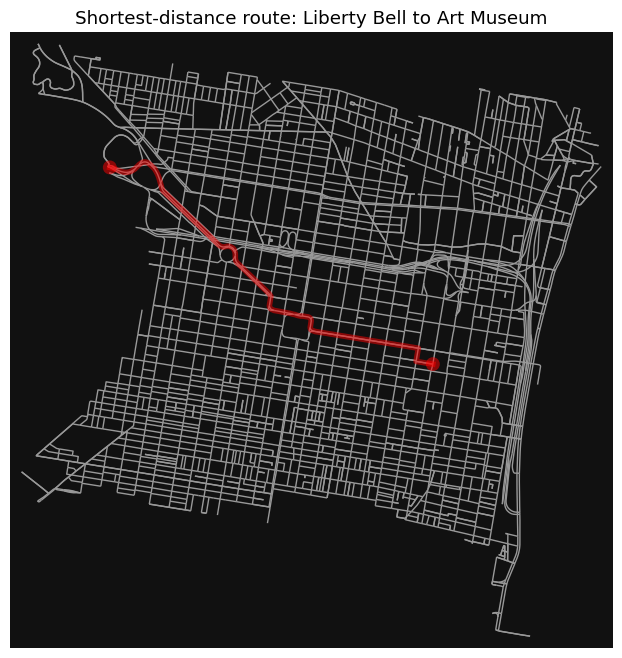

In [66]:
fig, ax = ox.plot_graph_route(G_cc, route1, node_size=0, show=False, close=False)
ax.set_title("Shortest-distance route: Liberty Bell to Art Museum")
plt.show()

Keep the interactive route example using the OSMnx 2.x function `ox.routing.route_to_gdf()`. Its `weight` selects the appropriate edge when parallel alternatives connect the same pair of nodes.

In [67]:
gdf_route = ox.routing.route_to_gdf(G_cc, route1, weight="length")
if SHOW_INTERACTIVE_MAPS:
    display(gdf_route.explore(tiles="CartoDB positron", color="red"))
else:
    display(gdf_route[["length", "geometry"]].head())

,,,length,geometry
u,v,key,,
3408446156,110217312,0,141.034741,"LINESTRING (-75.15058 39.94975, -75.15072 39.94977, -75...."
110217312,3425012161,0,5.819377,"LINESTRING (-75.15222 39.94996, -75.15221 39.95001)"
3425012161,109814427,0,105.409315,"LINESTRING (-75.15221 39.95001, -75.15212 39.9504, -75.1..."
109814427,5372039288,0,136.115485,"LINESTRING (-75.152 39.95094, -75.15211 39.95096, -75.15..."
5372039288,109814445,0,136.593417,"LINESTRING (-75.15357 39.95114, -75.15369 39.95115, -75...."


#### Finding the shortest estimated travel time

`add_edge_speeds()` uses available `maxspeed` tags and imputes missing speeds by road type. `add_edge_travel_times()` converts length and speed to seconds. The 30 km/h fallback below is an explicit classroom assumption for unresolved speeds.

These are **free-flow estimates**, not measured trip times or live traffic. Congestion, signals, parking, and turn restrictions are not modeled. **Predict:** must the shortest-distance route also minimize estimated time?

In [68]:
G_cc = ox.routing.add_edge_speeds(G_cc, fallback=30)
G_cc = ox.routing.add_edge_travel_times(G_cc)

In [69]:
edges = ox.convert.graph_to_gdfs(G_cc, nodes=False)

In [70]:
edges.head()

osmid      highway lanes                   name  \
u         v         key                                                        
109727439 109911666 0    132508434  residential     1      Bainbridge Street   
109727448 109727439 0     12109011  residential   NaN  South Colorado Street   
          110034229 0     12159387  residential   NaN       Fitzwater Street   
109727507 110024052 0    193364514  residential   NaN       Carpenter Street   
109728761 110274344 0    672312336  residential   NaN           Brown Street   

                         oneway reversed  ...  bridge tunnel  width  service  \
u         v         key                   ...                                  
109727439 109911666 0      True    False  ...     NaN    NaN    NaN      NaN   
109727448 109727439 0      True    False  ...     NaN    NaN    NaN      NaN   
          110034229 0      True    False  ...     NaN    NaN    NaN      NaN   
109727507 110024052 0      True    False  ...     NaN    NaN    NaN      NaN   
109728761 110274344 0      True    False  ...     NaN    NaN    NaN      NaN   

                         access junction  
u         v         key                   
109727439 109911666 0       NaN      NaN  
109727448 109727439 0       NaN      NaN  
          110034229 0       NaN      NaN  
109727507 110024052 0       NaN      NaN  
109728761 110274344 0       NaN      NaN  

[5 rows x 19 columns]

In [71]:
# A simplified edge can contain several highway tags; convert only for grouping.
road_type_summary = edges.assign(road_type=edges["highway"].astype(str))
road_type_summary.groupby("road_type")[["length", "speed_kph", "travel_time"]].mean().round(2)

,length,speed_kph,travel_time
road_type,,,
"['motorway_link', 'secondary_link']",224.67,40.23,20.10
"['motorway_link', 'tertiary']",151.60,40.23,13.56
"['residential', 'unclassified']",258.44,40.23,23.12
living_street,52.88,30.00,6.35
motorway,446.91,82.72,19.20
motorway_link,309.89,40.23,27.73
primary,102.96,44.39,8.38
primary_link,53.89,40.23,4.82
residential,80.96,38.47,7.60


In [72]:
route2 = ox.routing.shortest_path(G_cc, orig_node, dest_node, weight="travel_time")
if route2 is None:
    raise ValueError("No route exists for the travel-time query.")

# Select each route's actual edges using the cost that optimized that route.
gdf_route1 = ox.routing.route_to_gdf(G_cc, route1, weight="length")
gdf_route2 = ox.routing.route_to_gdf(G_cc, route2, weight="travel_time")

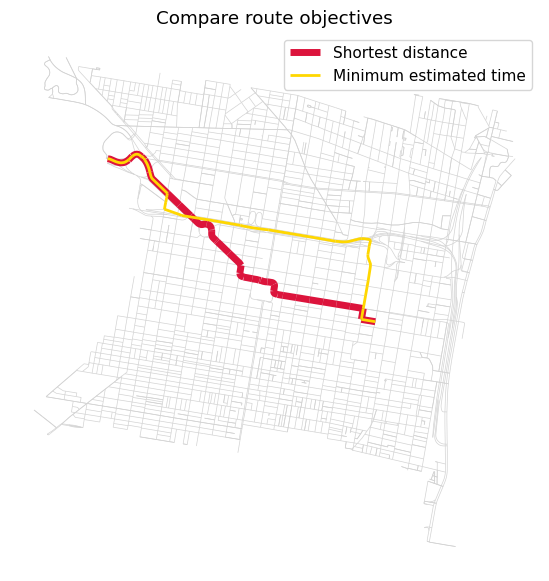

In [73]:
# Plot the selected geometries so parallel edges match the comparison table.
fig, ax = plt.subplots(figsize=(10, 7))
edges.to_crs(metric_crs).plot(ax=ax, color="lightgray", linewidth=0.5)
gdf_route1.to_crs(metric_crs).plot(ax=ax, color="crimson", linewidth=5, label="Shortest distance")
gdf_route2.to_crs(metric_crs).plot(ax=ax, color="gold", linewidth=2, label="Minimum estimated time")
ax.legend()
ax.set_title("Compare route objectives")
ax.set_axis_off()
plt.show()

Let's plot both in an interactive map:

In [74]:
if SHOW_INTERACTIVE_MAPS:
    m = gdf_route1.explore(tiles="CartoDB dark_matter", color="red")
    gdf_route2.explore(color="yellow", m=m)
    display(m)
else:
    print("Enable SHOW_INTERACTIVE_MAPS to compare both routes interactively.")

Enable SHOW_INTERACTIVE_MAPS to compare both routes interactively.


Let's compare to the two routes:

Distances:

In [75]:
meters_to_miles = 0.0006213712
route1_length = gdf_route1["length"].sum() * meters_to_miles
route2_length = gdf_route2["length"].sum() * meters_to_miles
print(f"Shortest-distance route: {route1_length:.2f} miles")
print(f"Minimum-time route: {route2_length:.2f} miles")

Shortest-distance route: 2.26 miles
Minimum-time route: 2.53 miles


Travel times:

In [76]:
# Measure BOTH costs on the same selected edges for each route.
seconds_to_mins = 1 / 60
route1_time = gdf_route1["travel_time"].sum() * seconds_to_mins
route2_time = gdf_route2["travel_time"].sum() * seconds_to_mins

Summarize:

In [77]:
comparison = pd.DataFrame({
    "Route": ["Shortest distance", "Minimum estimated time"],
    "Distance (miles)": [route1_length, route2_length],
    "Estimated time (minutes)": [route1_time, route2_time],
}).set_index("Route")
display(comparison.round(2))
assert route1_length <= route2_length + 1e-6
assert route2_time <= route1_time + 1e-6

,Distance (miles),Estimated time (minutes)
Route,,
Shortest distance,2.26,5.26
Minimum estimated time,2.53,4.76


## Part 2:  Pandana

"Pandas Network Analysis - dataframes of network queries, quickly"

Pandana complements OSMnx by efficiently querying network distances for many locations. We will reuse the OSM amenity data and walking graph already downloaded, then calculate the distance from each node to nearby amenities.

- [GitHub](https://github.com/UDST/pandana)
- [Jupyter Notebook Examples](https://github.com/UDST/pandana/tree/master/examples)
- [Documentation](http://udst.github.io/pandana/)

In [78]:
# If Pandana is missing, install it in the active environment and restart:
# %pip install pandana

In [79]:
import pandana as pnda

### Step 1: Get amenity data

Reuse the `amenities` GeoDataFrame downloaded in Part 1 rather than querying the same features through a second OSM loader. We keep the bounding-box, table-inspection, and amenity-count steps so you can follow how the data become inputs to Pandana.

In [80]:
print("Amenity fields:", amenities.columns.tolist())
print("Original amenity CRS:", amenities.crs)

Amenity fields: ['geometry', 'amenity', 'brand', 'brand:wikidata', 'name', 'operator', 'operator:wikidata', 'operator:wikipedia', 'short_name', 'addr:city', 'addr:housenumber', 'addr:postcode', 'addr:state', 'addr:street', 'air_conditioning', 'branch', 'cuisine', 'official_name', 'opening_hours', 'phone', 'ref', 'takeaway', 'website', 'created_by', 'source', 'alt_name', 'atm', 'contact:facebook', 'diet:vegetarian', 'payment:cash', 'payment:credit_cards', 'payment:debit_cards', 'wheelchair', 'brand:website', 'healthcare', 'internet_access', 'url', 'contact:phone', 'description', 'email', 'wikidata', 'brewery', 'contact:instagram', 'diet:vegan', 'education', 'ele', 'gnis:feature_id', 'religion', 'check_date', 'denomination', 'building', 'old_name', 'comment', 'operator:type', 'school', 'wikipedia', 'service_times', 'historic:amenity', 'name:en', 'social_facility', 'operator:short', 'operator:website', 'emergency', 'healthcare:speciality', 'bicycle_parking', 'capacity', 'covered', 'librar

Get the bounding box:

In [81]:
# Use the walking network's extent so the POIs and network cover the same area.
walk_nodes_ll = ox.convert.graph_to_gdfs(G_walk, edges=False)
boundary = tuple(walk_nodes_ll.total_bounds)
boundary, type(boundary)

((np.float64(-75.1809459),
  np.float64(39.9329666),
  np.float64(-75.1340392),
  np.float64(39.9689338)),
 tuple)

In [82]:
lng_min, lat_min, lng_max, lat_max = boundary
print("Bounding box order: longitude min, latitude min, longitude max, latitude max")

Bounding box order: longitude min, latitude min, longitude max, latitude max


In [83]:
poi_features = amenities.to_crs(4326).cx[lng_min:lng_max, lat_min:lat_max].copy()
valid = poi_features.geometry.notna() & ~poi_features.geometry.is_empty & poi_features.geometry.is_valid
poi_features = poi_features.loc[valid & poi_features["amenity"].notna()].copy()
# Represent polygon amenities by interior points, not centroids in degrees.
poi_projected = poi_features.to_crs(metric_crs)
poi_projected.geometry = poi_projected.geometry.representative_point()
poi_df = poi_projected.to_crs(4326).reset_index()
poi_df["lon"] = poi_df.geometry.x
poi_df["lat"] = poi_df.geometry.y

In [84]:
poi_df.head()

,element,id,geometry,amenity,brand,brand:wikidata,...,pedagogy,school:gender,statue,crossing:markings,lon,lat
0,node,110237774,POINT (-75.15662 39.9504),parking_entrance,NaN,NaN,...,NaN,NaN,NaN,NaN,-75.156620,39.950401
1,node,313440966,POINT (-75.16694 39.96394),car_sharing,NaN,NaN,...,NaN,NaN,NaN,NaN,-75.166939,39.963935
2,node,313440968,POINT (-75.17041 39.96398),car_sharing,NaN,NaN,...,NaN,NaN,NaN,NaN,-75.170407,39.963978
3,node,333786044,POINT (-75.15893 39.94086),restaurant,NaN,NaN,...,NaN,NaN,NaN,NaN,-75.158928,39.940858
4,node,333786095,POINT (-75.15736 39.94192),cafe,NaN,NaN,...,NaN,NaN,NaN,NaN,-75.157357,39.941924


In [85]:
len(poi_df)

3056

In [86]:
poi_df[["lat", "lon", "amenity"]].head(10)

,lat,lon,amenity
0,39.950401,-75.156620,parking_entrance
1,39.963935,-75.166939,car_sharing
2,39.963978,-75.170407,car_sharing
3,39.940858,-75.158928,restaurant
4,39.941924,-75.157357,cafe
5,39.942642,-75.157958,bank
6,39.943102,-75.160030,pharmacy
7,39.960730,-75.159457,pub
8,39.961567,-75.170303,car_sharing
9,39.965132,-75.156185,school


#### Explore the amenities in this region

For the full list of amenities, see the [OSM Wikipedia](https://wiki.openstreetmap.org/wiki/Key:amenity)

In [87]:
# Aggregate before charting to keep the output small and avoid Altair row limits.
counts = poi_df["amenity"].value_counts().rename_axis("amenity").reset_index(name="count")
chart = alt.Chart(counts).mark_bar().encode(
    y=alt.Y("amenity:N", sort="-x", title="Amenity"),
    x=alt.X("count:Q", title="Mapped OSM objects"),
    tooltip=["amenity:N", "count:Q"],
).properties(title="Amenity types in the study area")
chart

alt.Chart(...)

### Step 2: Create a Pandana network

Convert the existing walking graph to tables. Edge costs are OSMnx lengths in meters. The graph already has both travel directions, so `twoway=False` preserves these records without adding duplicates.

Parallel edges with the same endpoints are reduced to the shortest for distance-only analysis. This keeps the lesson focused on Pandana rather than a second download API.

In [88]:
# No osmnet download is needed: inspect the walking graph we already have.
print(f"Walking graph: {len(G_walk):,} nodes and {G_walk.number_of_edges():,} directed edges")

Walking graph: 10,655 nodes and 31,854 directed edges


In [89]:
G_walk_projected = ox.projection.project_graph(G_walk, to_crs=metric_crs)
walk_nodes, walk_edges = ox.convert.graph_to_gdfs(G_walk_projected)
links = walk_edges.reset_index()[["u", "v", "length"]]
links = links.sort_values("length").drop_duplicates(["u", "v"])
links = links.loc[links.u != links.v].reset_index(drop=True)
net = pnda.Network(
    walk_nodes.geometry.x, walk_nodes.geometry.y,
    links["u"], links["v"], links[["length"]], twoway=False,
)

Generating contraction hierarchies with 1 threads.
Setting CH node vector of size 10655
Setting CH edge vector of size 31500
Range graph removed 31500 edges of 63000
. 10% . 20% . 30% . 40% . 50% . 60% . 70% . 80% . 90% . 100%


### Step 3: Tell the network the location of amenities

`net.set_pois()` registers each amenity category for subsequent queries. We retain the four examples: restaurant, bar, school, and car sharing.

Use projected point coordinates matching the network. POIs are snapped to nodes; the off-network connection is not part of Pandana's distance. The 100-meter snapping cutoff below is a classroom assumption. Inspect the exclusions before using results for a real study.

In [90]:
max_distance = 2000  # Network search distance, in meters.
num_pois = 10
AMENITIES = ["restaurant", "bar", "school", "car_sharing"]
net.precompute(max_distance)
poi_metric = poi_df.to_crs(metric_crs)
_, snap_m = ox.distance.nearest_nodes(
    G_walk_projected, X=poi_metric.geometry.x, Y=poi_metric.geometry.y, return_dist=True
)
poi_metric["snap_m"] = snap_m
print(f"POIs excluded beyond 100 m from a node: {(poi_metric.snap_m > 100).sum():,}")
poi_metric = poi_metric.loc[poi_metric.snap_m <= 100].copy()
registered_amenities = []
for amenity in AMENITIES:
    subset = poi_metric.loc[poi_metric["amenity"].eq(amenity)]
    print(f"{amenity}: {len(subset):,} mapped objects")
    if subset.empty:
        continue
    net.set_pois(amenity, max_distance, num_pois, subset.geometry.x, subset.geometry.y)
    registered_amenities.append(amenity)

POIs excluded beyond 100 m from a node: 11
restaurant: 387 mapped objects
bar: 70 mapped objects
school: 50 mapped objects
car_sharing: 80 mapped objects


In [91]:
fig_kwargs = {"facecolor": "white", "figsize": (8, 7)}
plot_kwargs = {"markersize": 5, "alpha": 0.9, "cmap": "viridis_r"}

### Step 4: Plot the walking distance to the nearest POI

For each network node, query the distance to the nth nearest mapped amenity, join the distance to node coordinates, and map it.

Use `max_distance=np.nan` in the query to distinguish **not found within the cutoff** from a measured distance exactly equal to the cutoff. Missing results can reflect too few mapped objects, disconnected paths, or the study boundary—not necessarily no real-world amenity.

#### 4.1 Query distances with `net.nearest_pois()`

In [92]:
amenity = "bar"
if amenity not in registered_amenities:
    raise ValueError("No bars were found; select a registered amenity category.")
access = net.nearest_pois(
    distance=max_distance, category=amenity, num_pois=num_pois, max_distance=np.nan
)

In [93]:
access.tail(10)  # Columns 1–10 correspond to the nearest through tenth-nearest POI.

,1,2,3,4,5,6,7,8,9,10
osmid,,,,,,,,,,
13119729382,343.708008,502.050995,505.541992,607.348999,621.700989,788.398010,824.708008,892.562988,917.619019,1015.017029
13152105637,469.886993,480.798004,616.315002,726.325012,809.336975,974.054993,1272.135986,1274.853027,1275.818970,1286.416016
13152105636,463.376007,474.286987,609.804016,719.814026,802.825989,967.544006,1265.625000,1268.342041,1269.307983,1279.905029
13152105632,465.343994,476.255005,611.771973,721.781982,804.794006,969.512024,1267.593018,1270.310059,1271.276001,1281.873047
13152105635,465.251007,476.161987,611.679016,721.689026,804.700989,969.419006,1267.500000,1270.217041,1271.182983,1281.780029
13152542790,147.013000,218.817993,229.367004,243.223007,390.628998,546.742004,1033.467041,1081.383057,1081.383057,1495.083008
13152610920,568.301025,905.833984,930.239014,940.978027,967.780029,1022.705017,1046.093018,1092.702026,1134.990967,1242.312988
13152610923,549.263000,886.796021,911.200989,922.372009,948.742004,1021.380005,1027.055054,1091.376953,1148.942017,1256.264038
13152684131,607.216980,741.578003,825.379028,840.226990,1087.027954,1156.817017,1164.547974,1404.442017,1458.333008,1469.422974


#### 4.2 Merge coordinates of network nodes with distances to nearest POIs

In [94]:
net.nodes_df.head()

,x,y
osmid,,
109727353,485223.173841,4.420539e+06
109727357,485198.570945,4.420404e+06
110024116,485270.834427,4.420531e+06
109924749,485183.209066,4.420545e+06
109924757,485158.818726,4.420411e+06


In [95]:
access.head()

,1,2,3,4,5,6,7,8,9,10
osmid,,,,,,,,,,
109727353,191.190994,763.151001,1170.654053,1220.255981,1267.386963,1292.282959,1340.516968,1388.668945,1535.485962,1629.515015
109727357,327.695007,899.655029,1307.157959,1356.760010,1403.890991,1428.911011,1477.020996,1525.172974,1671.989990,1766.019043
110024116,142.947998,714.908020,1122.411011,1172.012939,1219.144043,1292.274048,1336.762939,1340.426025,1487.243042,1581.271973
109924749,231.643997,803.604004,1211.107056,1251.829956,1260.708984,1307.839966,1380.969971,1429.121948,1575.938965,1669.968018
109924757,367.907013,939.867004,1347.369995,1388.698975,1396.972046,1444.103027,1517.233032,1565.385010,1712.202026,1806.230957


In [96]:
nodes = net.nodes_df.join(access)
nodes = gpd.GeoDataFrame(
    nodes, geometry=gpd.points_from_xy(nodes["x"], nodes["y"]), crs=metric_crs
)

In [97]:
nodes.head()

,x,y,1,2,3,4,...,6,7,8,9,10,geometry
osmid,,,,,,,,,,,,,
109727353,485223.173841,4.420539e+06,191.190994,763.151001,1170.654053,1220.255981,...,1292.282959,1340.516968,1388.668945,1535.485962,1629.515015,POINT (485223.174 4420538.576)
109727357,485198.570945,4.420404e+06,327.695007,899.655029,1307.157959,1356.760010,...,1428.911011,1477.020996,1525.172974,1671.989990,1766.019043,POINT (485198.571 4420404.249)
110024116,485270.834427,4.420531e+06,142.947998,714.908020,1122.411011,1172.012939,...,1292.274048,1336.762939,1340.426025,1487.243042,1581.271973,POINT (485270.834 4420530.504)
109924749,485183.209066,4.420545e+06,231.643997,803.604004,1211.107056,1251.829956,...,1307.839966,1380.969971,1429.121948,1575.938965,1669.968018,POINT (485183.209 4420545.346)
109924757,485158.818726,4.420411e+06,367.907013,939.867004,1347.369995,1388.698975,...,1444.103027,1517.233032,1565.385010,1712.202026,1806.230957,POINT (485158.819 4420410.83)


#### 4.3 Plot the results

Keep a reusable function because the following examples compare several amenity types and ranks. The function honors its `distance` argument, uses a consistent color scale, and shows missing results in gray. Red stars show the mapped amenities.

In [98]:
def plot_walking_distance(net, amenity, distance=1000, n=1):
    """Plot distance to the nth nearest mapped POI within the search cutoff."""
    if not 0 < distance <= max_distance or not 1 <= n <= num_pois:
        raise ValueError("Search distance or POI rank exceeds the registered limits.")
    fig, ax = plt.subplots(**fig_kwargs)
    if amenity not in registered_amenities:
        ax.text(0.5, 0.5, f"No mapped {amenity} POIs in the study area", ha="center")
        ax.set_axis_off()
        return ax
    access = net.nearest_pois(
        distance=distance, category=amenity, num_pois=n, max_distance=np.nan
    )
    mapped = walk_nodes.join(access)
    mapped.plot(ax=ax, color="lightgray", markersize=5)
    found = mapped.loc[mapped[n].notna()]
    if not found.empty:
        found.plot(ax=ax, column=n, vmin=0, vmax=distance, **plot_kwargs)
    pois = poi_metric.loc[poi_metric["amenity"].eq(amenity)]
    pois.plot(ax=ax, color="crimson", marker="*", markersize=35, zorder=3)
    scale = plt.cm.ScalarMappable(norm=plt.Normalize(0, distance), cmap="viridis_r")
    fig.colorbar(scale, ax=ax, shrink=0.8, label="Network distance (meters)")
    ax.set_axis_off()
    ax.text(0.01, 0.01, f"{mapped[n].notna().mean():.0%} of nodes have a result; gray = not found",
            transform=ax.transAxes, fontsize=9, bbox={"facecolor": "white", "alpha": 0.8})
    return ax

### Evaluating amenity choice

The difference between maps to the nearest amenity and for example, the 5th nearest amenity tells us about the options consumers have

#### Example: bars

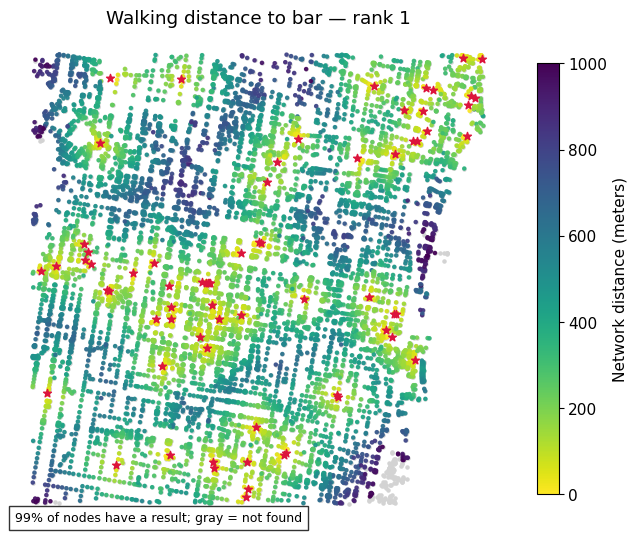

In [99]:
ax = plot_walking_distance(net, "bar", distance=1000, n=1)
ax.set_title("Walking distance to bar — rank 1")
plt.show()

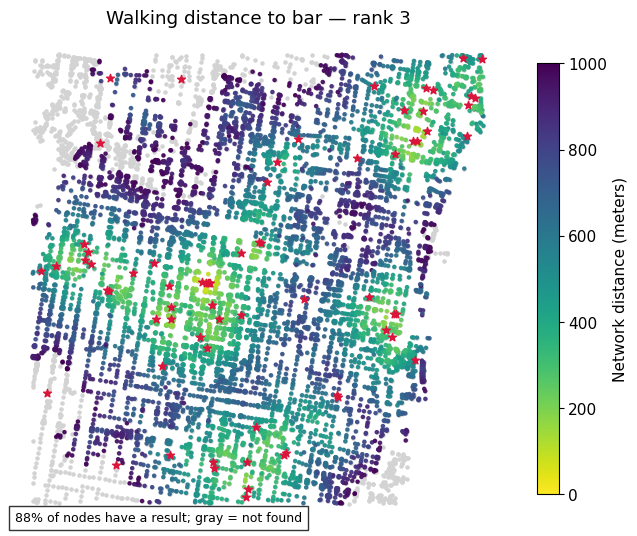

In [100]:
ax = plot_walking_distance(net, "bar", distance=1000, n=3)
ax.set_title("Walking distance to bar — rank 3")
plt.show()

#### Example: schools

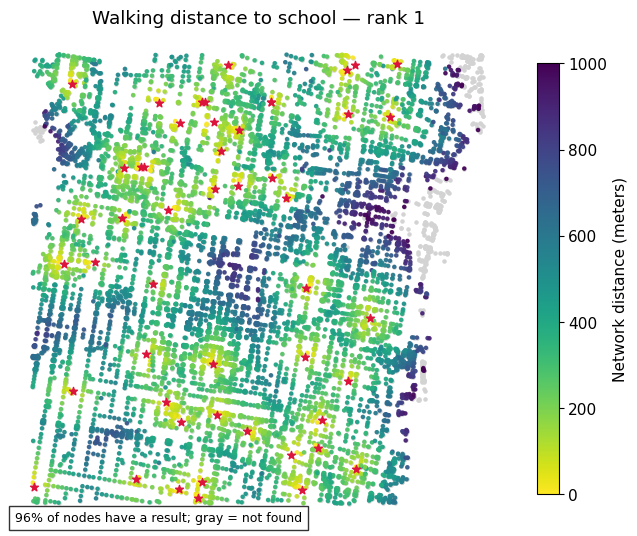

In [101]:
ax = plot_walking_distance(net, "school", distance=1000, n=1)
ax.set_title("Walking distance to school — rank 1")
plt.show()

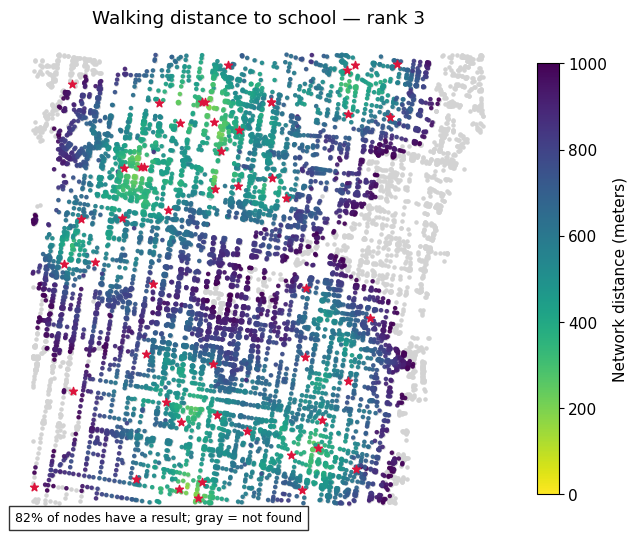

In [102]:
ax = plot_walking_distance(net, "school", distance=1000, n=3)
ax.set_title("Walking distance to school — rank 3")
plt.show()

#### Example: restaurants

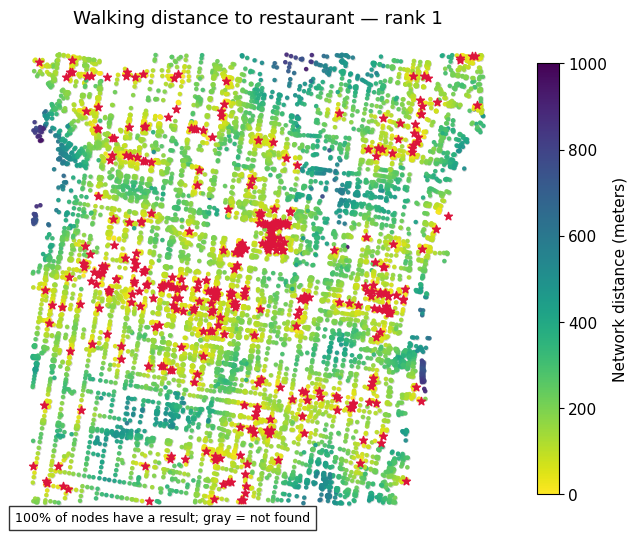

In [103]:
ax = plot_walking_distance(net, "restaurant", distance=1000, n=1)
ax.set_title("Walking distance to restaurant — rank 1")
plt.show()

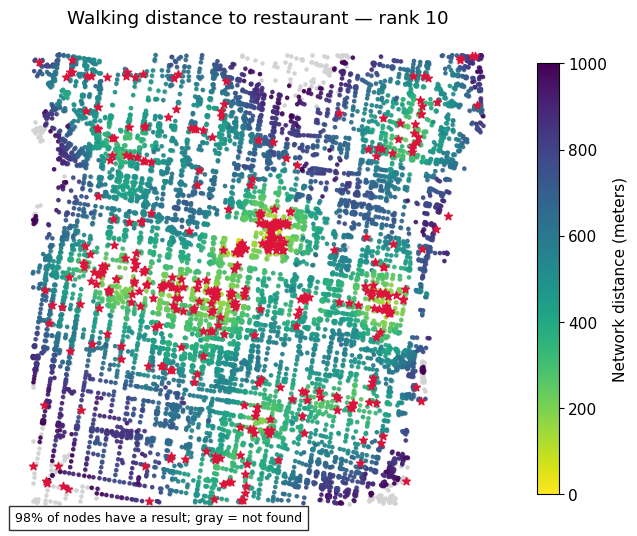

In [104]:
ax = plot_walking_distance(net, "restaurant", distance=1000, n=10)
ax.set_title("Walking distance to restaurant — rank 10")
plt.show()

#### Example: car sharing

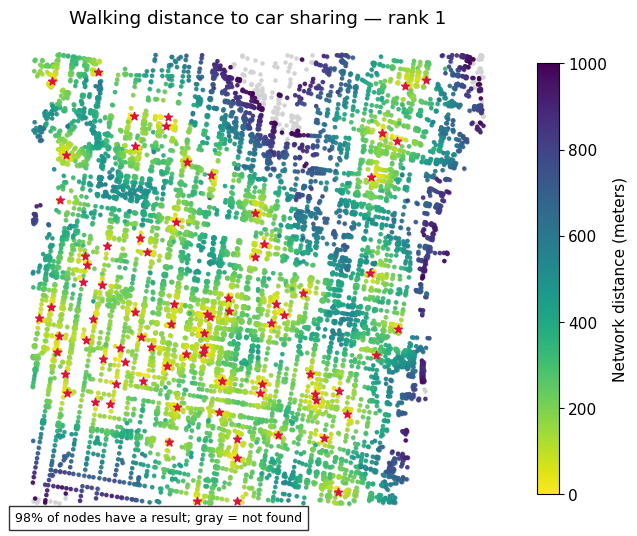

In [105]:
ax = plot_walking_distance(net, "car_sharing", distance=1000, n=1)
ax.set_title("Walking distance to car sharing — rank 1")
plt.show()

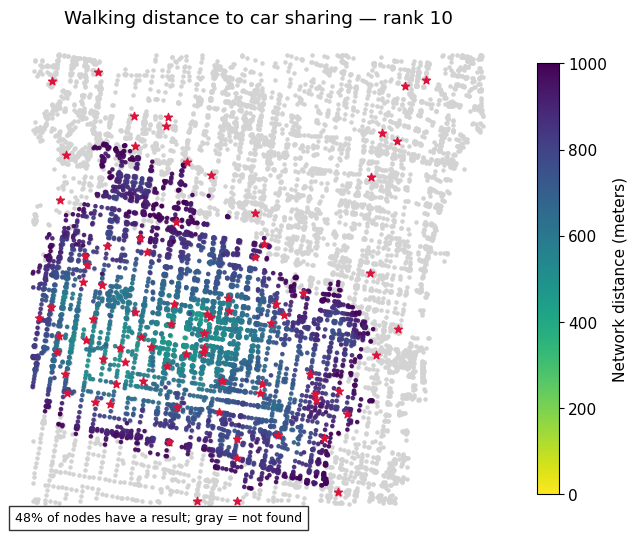

In [106]:
ax = plot_walking_distance(net, "car_sharing", distance=1000, n=10)
ax.set_title("Walking distance to car sharing — rank 10")
plt.show()

## At-home exercise: Explore amenities in a neighborhood of your choice

Keep the same workflow: obtain a boundary, choose a travel network, inspect amenity tags, register POIs, and compare access to the first and a later-ranked amenity.

1. Change the amenity or query distance and explain how the map changes.
2. Check snapping distances and distinguish missing results from observed long distances.
3. Download an area larger than your reporting neighborhood to reduce boundary effects.
4. Explain limitations: OSM completeness, duplicate representations of a facility, approximate entrances, and the absence of population weights. “Tenth nearest” refers to mapped objects unless you deduplicate facilities.

Use the [OSM amenity reference](https://wiki.openstreetmap.org/wiki/Key:amenity), [OSMnx documentation](https://osmnx.readthedocs.io/en/stable/user-reference.html), and [Pandana API](https://udst.github.io/pandana/network.html).

Data and maps: © [OpenStreetMap contributors](https://www.openstreetmap.org/copyright), ODbL. Cached results are historical snapshots, not a current inventory. Planning districts: City of Philadelphia, via [Open Data Philly](https://opendataphilly.org/datasets/planning-districts/).